# Bit-Plane Slicing and Histogram-Based Image Enhancement

## 1. Lab Overview

This lab explores bit-plane slicing and histogram-based techniques for image enhancement. It covers extracting, visualizing, comparing, and reconstructing bit planes; generating and interpreting histograms; applying global histogram enhancement; and implementing local enhancement using histogram and statistical methods.

The experiments begin with grayscale images and extend relevant techniques to color images while minimizing unwanted color distortion.

## 2. Learning Outcomes

By the end of this lab, you will be able to:

1. Extract and visualize all eight bit planes of an 8-bit grayscale image.
2. Explain the difference between most significant bits (MSBs) and least significant bits (LSBs).
3. Generate and interpret image histograms and normalized histograms.
4. Apply histogram equalization, stretching, and shrinking.
5. Compare global and local histogram enhancement techniques.
6. Implement local enhancement using local mean and standard deviation.
7. Apply suitable enhancement techniques to color images while minimizing color distortion.
8. Analyze enhancement results using image displays, histograms, and intensity statistics.

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from scipy.ndimage import uniform_filter
 
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
 


OpenCV: 5.0.0
NumPy: 2.5.3


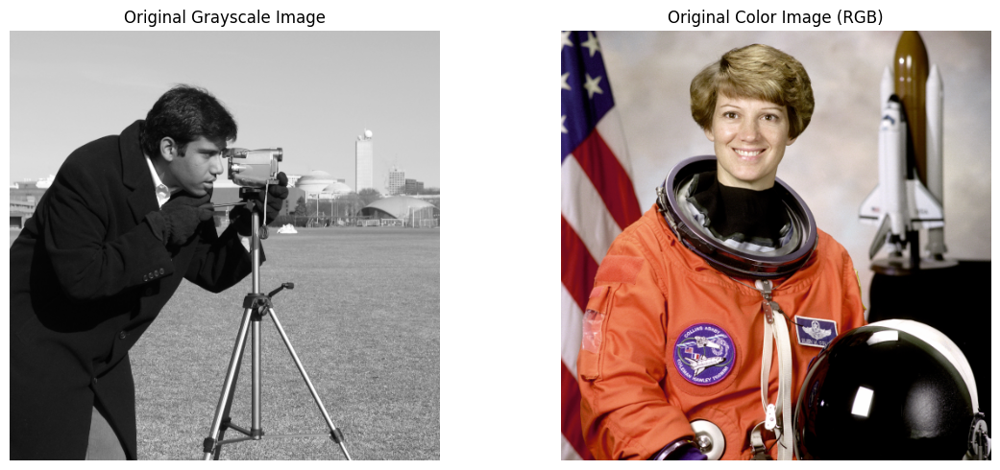

Grayscale shape/range: (512, 512) 0 255
Color shape/range: (512, 512, 3) 0 255


In [4]:
gray_img = data.camera().astype(np.uint8)       # Grayscale
color_img = data.astronaut().astype(np.uint8)   # RGB
 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(gray_img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Grayscale Image")
axes[0].axis("off")

axes[1].imshow(color_img)
axes[1].set_title("Original Color Image (RGB)")
axes[1].axis("off")
plt.tight_layout()
plt.show()
 
print("Grayscale shape/range:", gray_img.shape, gray_img.min(), gray_img.max())
print("Color shape/range:", color_img.shape, color_img.min(), color_img.max())


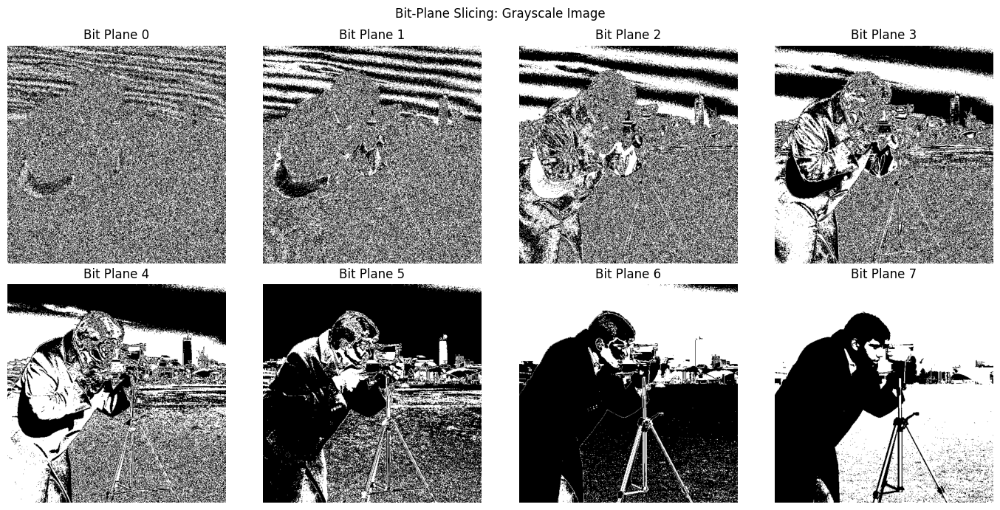

In [5]:
# Part A — Bit-Plane Slicing and Analysis
# Extract and Visualize All Eight Bit Planes

bit_planes = []
for k in range(8):
    plane = ((gray_img >> k) & 1) * 255
    bit_planes.append(plane.astype(np.uint8))
 
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for k, ax in enumerate(axes.flat):
    ax.imshow(bit_planes[k], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Bit Plane {k}")
    ax.axis("off")
plt.suptitle("Bit-Plane Slicing: Grayscale Image")
plt.tight_layout()
plt.show()


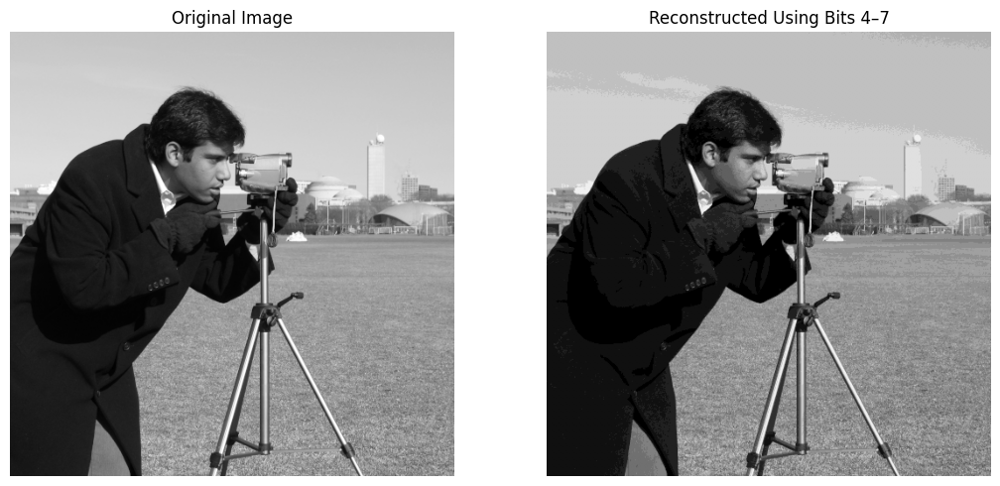

In [6]:
# Reconstruct Using Selected Bit Planes
# Keep bits 7, 6, 5, and 4: binary mask 11110000 = decimal 240
reconstructed = gray_img & 240
 
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(gray_img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image"); axes[0].axis("off")
axes[1].imshow(reconstructed, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Reconstructed Using Bits 4–7"); axes[1].axis("off")
plt.tight_layout(); plt.show()


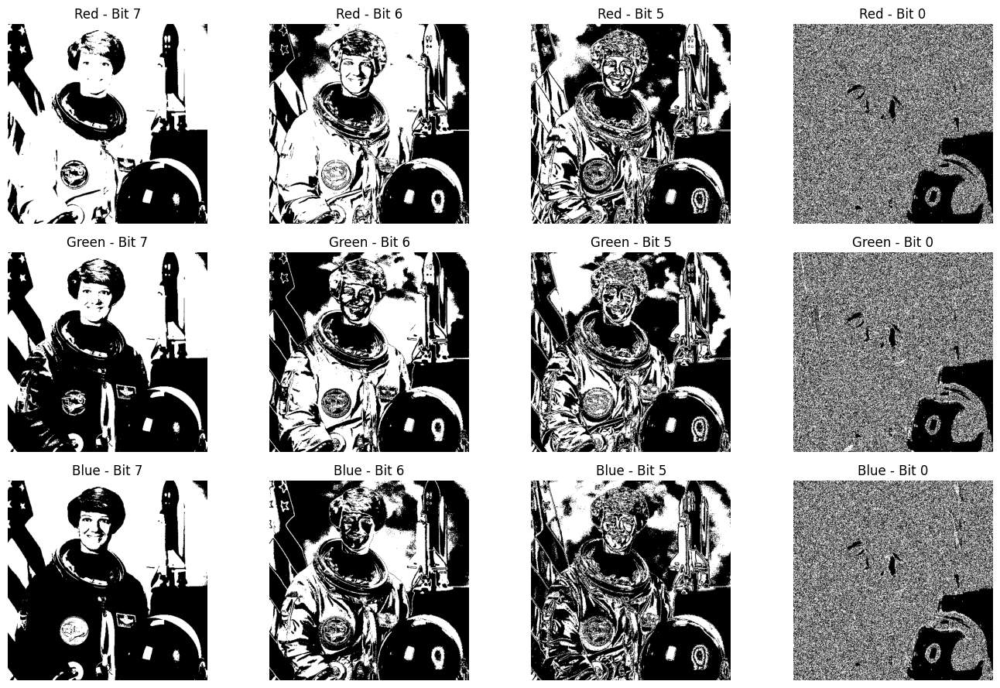

In [7]:
# Bit-Plane Slicing for a Color Image
channel_names = ["Red", "Green", "Blue"]
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for c in range(3):
    for j, k in enumerate([7, 6, 5, 0]):
        plane = ((color_img[:, :, c] >> k) & 1) * 255
        axes[c, j].imshow(plane, cmap="gray", vmin=0, vmax=255)
        axes[c, j].set_title(f"{channel_names[c]} - Bit {k}")
        axes[c, j].axis("off")
plt.tight_layout(); plt.show()


## Bit-Plane Slicing for a Color Image

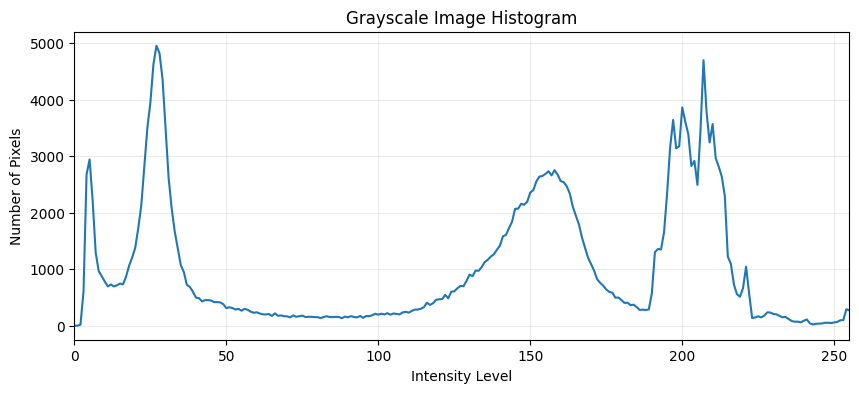

In [8]:
# Generate a Grayscale Histogram
hist = cv2.calcHist([gray_img], [0], None, [256], [0, 256]).flatten()
plt.figure(figsize=(10, 4))
plt.plot(np.arange(256), hist)
plt.title("Grayscale Image Histogram")
plt.xlabel("Intensity Level"); plt.ylabel("Number of Pixels")
plt.xlim(0, 255); plt.grid(alpha=0.25); plt.show()


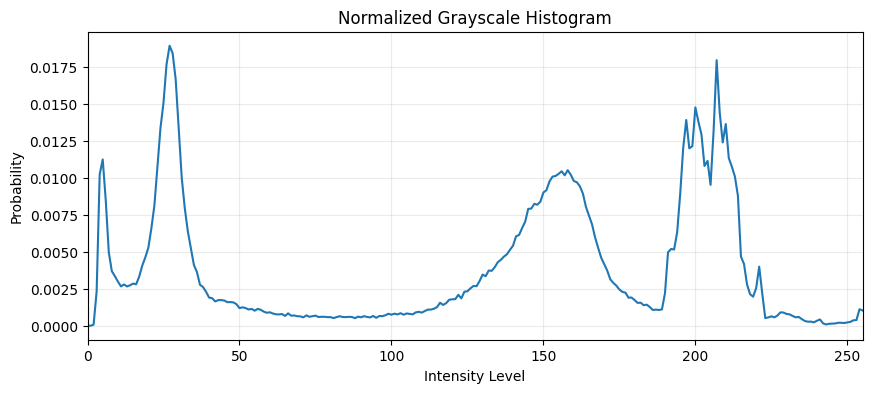

Sum of normalized histogram: 1.0


In [9]:
# Generate a Normalized Histogram
normalized_hist = hist / hist.sum()
plt.figure(figsize=(10, 4))
plt.plot(np.arange(256), normalized_hist)
plt.title("Normalized Grayscale Histogram")
plt.xlabel("Intensity Level"); plt.ylabel("Probability")
plt.xlim(0, 255); plt.grid(alpha=0.25); plt.show()
print("Sum of normalized histogram:", normalized_hist.sum())


In [10]:
# Calculate and Interpret Image Statistics
print("Minimum intensity:", np.min(gray_img))
print("Maximum intensity:", np.max(gray_img))
print("Mean intensity:", np.mean(gray_img))
print("Standard deviation:", np.std(gray_img))


Minimum intensity: 0
Maximum intensity: 255
Mean intensity: 129.06072616577148
Standard deviation: 73.64484655630552


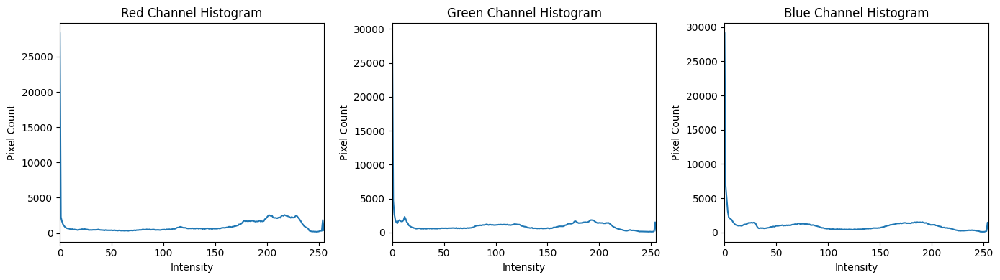

In [11]:
# Histograms for Color Channels
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
channel_names = ["Red", "Green", "Blue"]
for c, ax in enumerate(axes):
    channel = color_img[:, :, c]
    h = cv2.calcHist([channel], [0], None, [256], [0, 256]).flatten()
    ax.plot(np.arange(256), h)
    ax.set_title(f"{channel_names[c]} Channel Histogram")
    ax.set_xlabel("Intensity"); ax.set_ylabel("Pixel Count")
    ax.set_xlim(0, 255)
plt.tight_layout(); plt.show()


## Part C — Global Histogram Enhancement

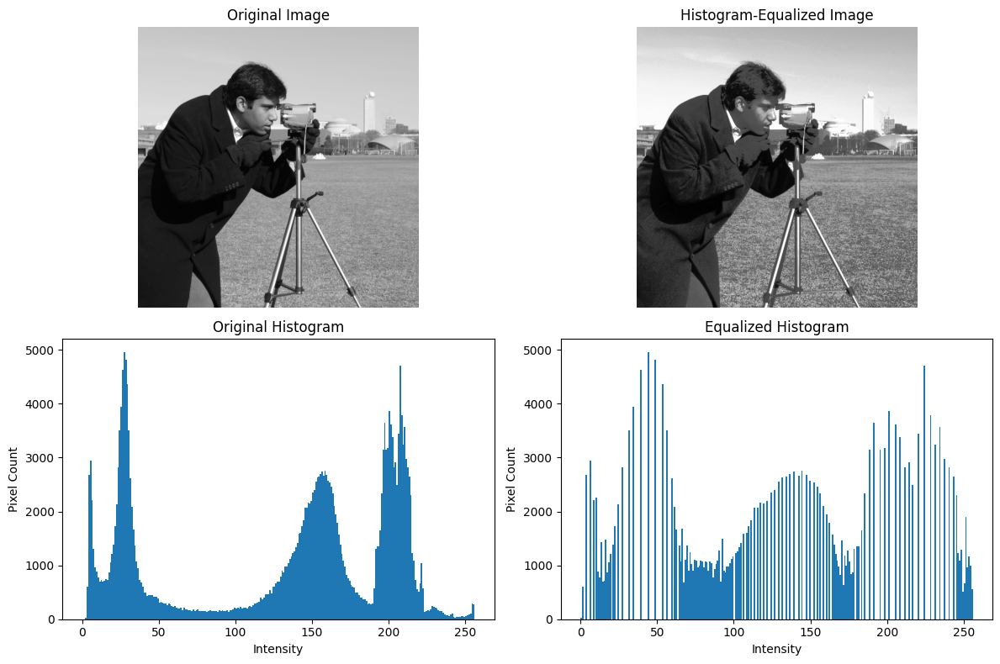

In [12]:
# Histogram Equalization for Grayscale
equalized_gray = cv2.equalizeHist(gray_img)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].imshow(gray_img, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Image")
axes[0, 1].imshow(equalized_gray, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Histogram-Equalized Image")
axes[1, 0].hist(gray_img.ravel(), bins=256, range=(0, 256))
axes[1, 0].set_title("Original Histogram")
axes[1, 1].hist(equalized_gray.ravel(), bins=256, range=(0, 256))
axes[1, 1].set_title("Equalized Histogram")
for ax in axes.flat:
    if ax in axes[0]: ax.axis("off")
    else:
        ax.set_xlabel("Intensity"); ax.set_ylabel("Pixel Count")
plt.tight_layout(); plt.show()


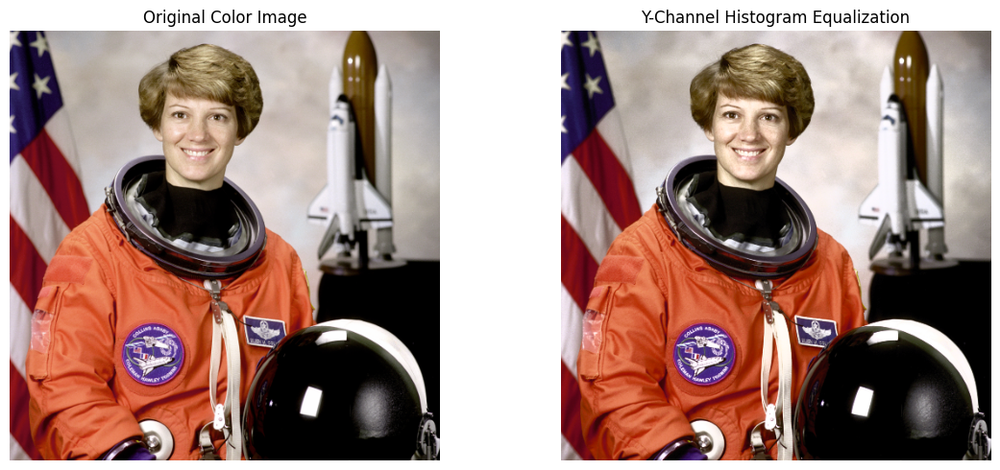

In [13]:
# Histogram Equalization for a Color Image
# color_img is RGB (from scikit-image)
ycrcb = cv2.cvtColor(color_img, cv2.COLOR_RGB2YCrCb)
y, cr, cb = cv2.split(ycrcb)
y_equalized = cv2.equalizeHist(y)
color_equalized = cv2.cvtColor(
    cv2.merge([y_equalized, cr, cb]), cv2.COLOR_YCrCb2RGB
)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(color_img); axes[0].set_title("Original Color Image"); axes[0].axis("off")
axes[1].imshow(color_equalized); axes[1].set_title("Y-Channel Histogram Equalization"); axes[1].axis("off")
plt.tight_layout(); plt.show()


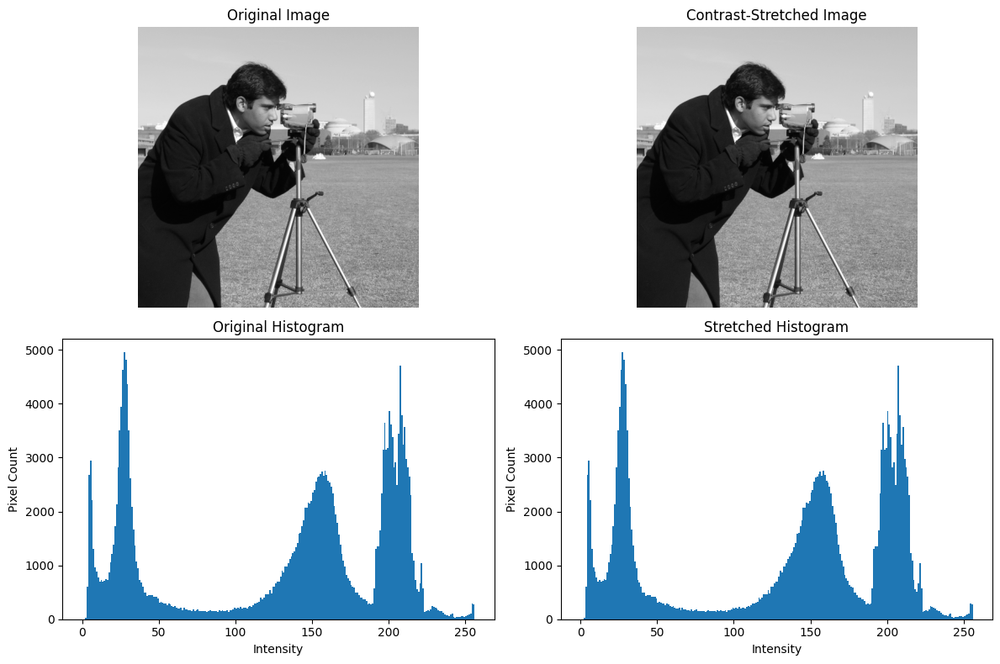

In [14]:
# Histogram Stretching
def histogram_stretch(img, out_min=0, out_max=255):
    img_f = img.astype(np.float32)
    r_min, r_max = float(img_f.min()), float(img_f.max())
    if r_max == r_min:
        return np.full_like(img, out_min, dtype=np.uint8)
    stretched = ((img_f - r_min) / (r_max - r_min)
                 * (out_max - out_min) + out_min)
    return np.clip(stretched, 0, 255).astype(np.uint8)
 
stretched_gray = histogram_stretch(gray_img)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].imshow(gray_img, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Image")
axes[0, 1].imshow(stretched_gray, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-Stretched Image")
axes[1, 0].hist(gray_img.ravel(), bins=256, range=(0, 256))
axes[1, 0].set_title("Original Histogram")
axes[1, 1].hist(stretched_gray.ravel(), bins=256, range=(0, 256))
axes[1, 1].set_title("Stretched Histogram")
for ax in axes.flat:
    if ax in axes[0]: ax.axis("off")
    else:
        ax.set_xlabel("Intensity"); ax.set_ylabel("Pixel Count")
plt.tight_layout(); plt.show()



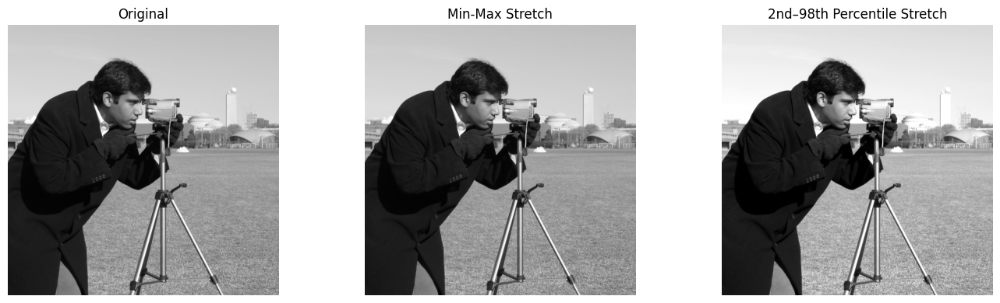

In [15]:
# Full-Range Versus Percentile Stretching
def percentile_stretch(img, low_percentile=2, high_percentile=98):
    img_f = img.astype(np.float32)
    r_min, r_max = np.percentile(img_f, [low_percentile, high_percentile])
    if r_max <= r_min:
        return img.copy()
    result = (img_f - r_min) * 255.0 / (r_max - r_min)
    return np.clip(result, 0, 255).astype(np.uint8)
 
percentile_gray = percentile_stretch(gray_img)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, im, title in zip(
    axes, [gray_img, stretched_gray, percentile_gray],
    ["Original", "Min-Max Stretch", "2nd–98th Percentile Stretch"]
):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()


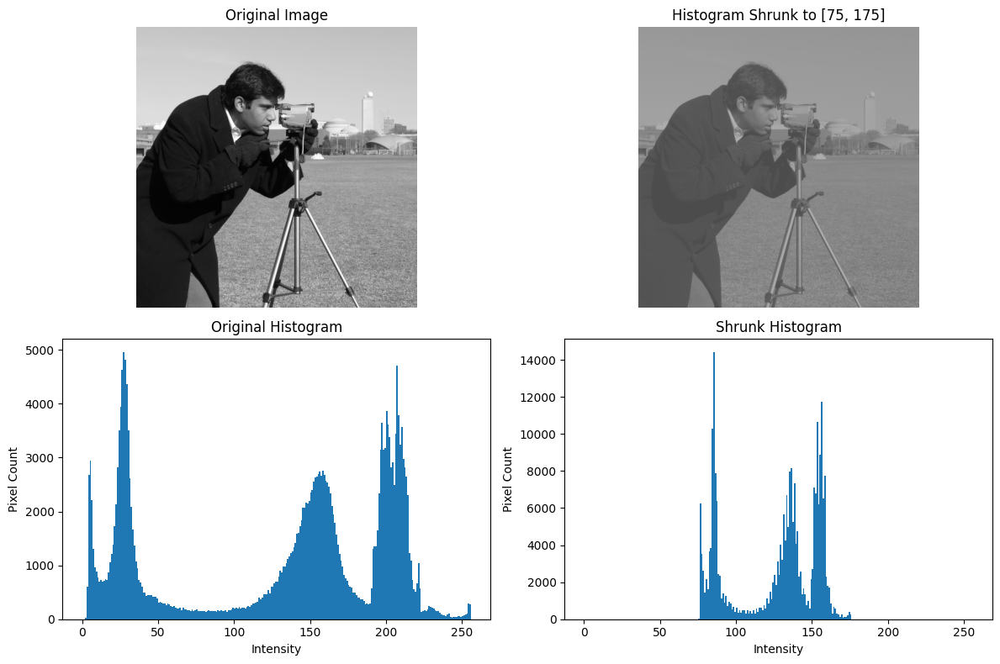

Output minimum: 75
Output maximum: 175


In [16]:
# Histogram Shrinking
shrunk_gray = histogram_stretch(gray_img, out_min=75, out_max=175)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].imshow(gray_img, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Image")
axes[0, 1].imshow(shrunk_gray, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Histogram Shrunk to [75, 175]")
axes[1, 0].hist(gray_img.ravel(), bins=256, range=(0, 256))
axes[1, 0].set_title("Original Histogram")
axes[1, 1].hist(shrunk_gray.ravel(), bins=256, range=(0, 256))
axes[1, 1].set_title("Shrunk Histogram")
for ax in axes.flat:
    if ax in axes[0]: ax.axis("off")
    else:
        ax.set_xlabel("Intensity"); ax.set_ylabel("Pixel Count")
plt.tight_layout(); plt.show()
print("Output minimum:", shrunk_gray.min())
print("Output maximum:", shrunk_gray.max())


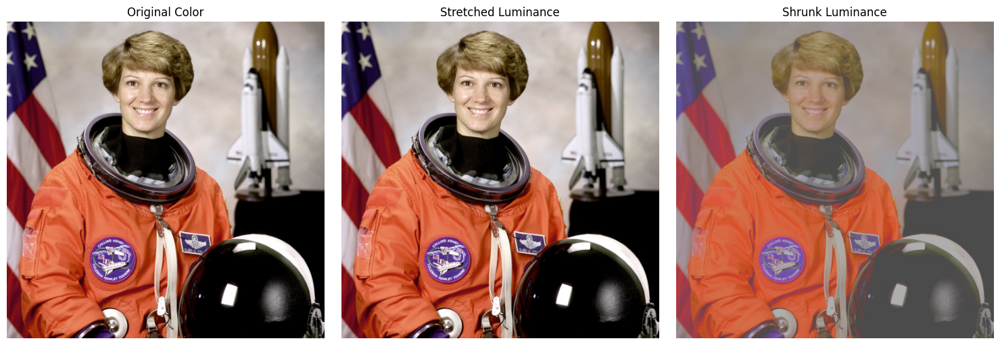

In [17]:
# Stretching and Shrinking for Color Images
def process_color_luminance(rgb_img, operation, out_min=0, out_max=255):
    ycrcb = cv2.cvtColor(rgb_img, cv2.COLOR_RGB2YCrCb)
    y, cr, cb = cv2.split(ycrcb)
    if operation in ("stretch", "shrink"):
        y_new = histogram_stretch(y, out_min, out_max)
    else:
        raise ValueError("Operation must be 'stretch' or 'shrink'.")
    return cv2.cvtColor(cv2.merge([y_new, cr, cb]), cv2.COLOR_YCrCb2RGB)
 
color_stretched = process_color_luminance(color_img, "stretch", 0, 255)
color_shrunk = process_color_luminance(color_img, "shrink", 75, 175)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, im, title in zip(
    axes, [color_img, color_stretched, color_shrunk],
    ["Original Color", "Stretched Luminance", "Shrunk Luminance"]
):
    ax.imshow(im); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()


## Part D — Local Histogram Processing

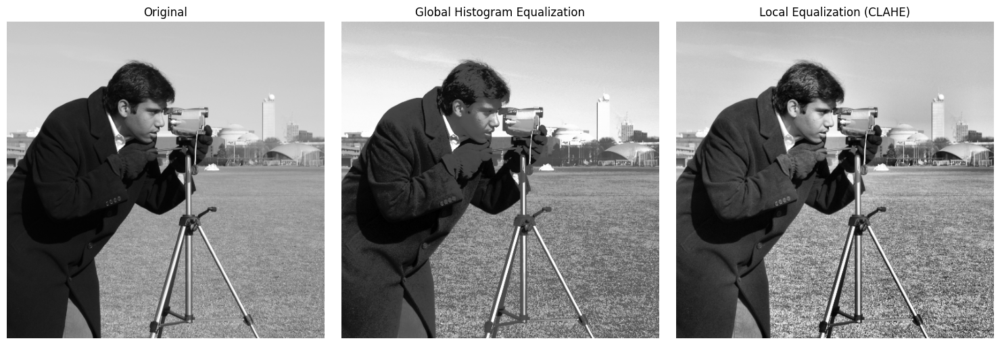

In [18]:
# Compare Global Equalization with CLAHE
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
local_equalized = clahe.apply(gray_img)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(gray_img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(equalized_gray, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Global Histogram Equalization"); axes[1].axis("off")
axes[2].imshow(local_equalized, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Local Equalization (CLAHE)"); axes[2].axis("off")
plt.tight_layout(); plt.show()


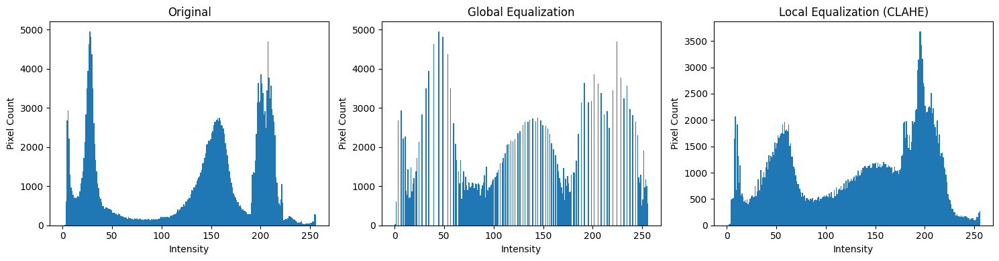

In [19]:
# Compare Histograms and Analyze Results
images = [gray_img, equalized_gray, local_equalized]
titles = ["Original", "Global Equalization", "Local Equalization (CLAHE)"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, img, title in zip(axes, images, titles):
    ax.hist(img.ravel(), bins=256, range=(0, 256))
    ax.set_title(title); ax.set_xlabel("Intensity"); ax.set_ylabel("Pixel Count")
plt.tight_layout(); plt.show()


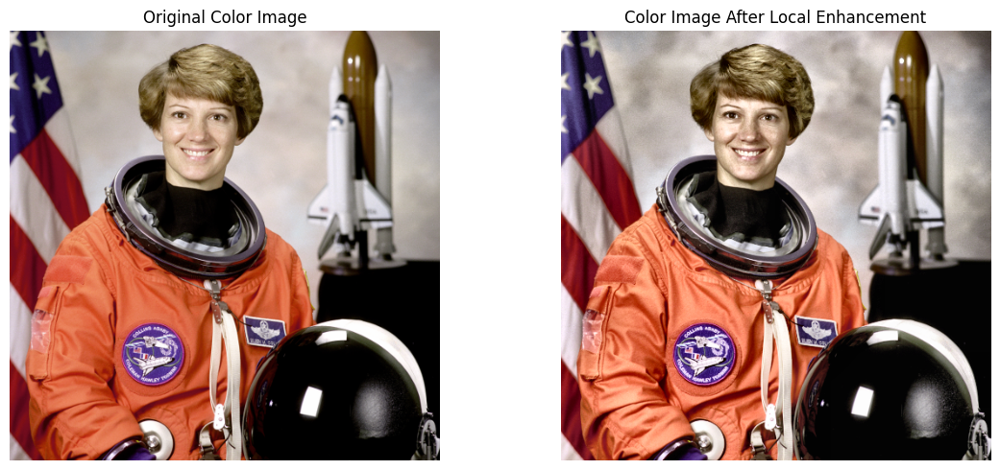

In [20]:
# Apply CLAHE to a Color Image
ycrcb = cv2.cvtColor(color_img, cv2.COLOR_RGB2YCrCb)
y, cr, cb = cv2.split(ycrcb)
clahe_color = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
y_local = clahe_color.apply(y)
color_local_equalized = cv2.cvtColor(
    cv2.merge([y_local, cr, cb]), cv2.COLOR_YCrCb2RGB
)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(color_img); axes[0].set_title("Original Color Image"); axes[0].axis("off")
axes[1].imshow(color_local_equalized); axes[1].set_title("Color Image After Local Enhancement"); axes[1].axis("off")
plt.tight_layout(); plt.show()


## Part E — Local Enhancement Using Statistical Parameters

Global mean: 129.06072998046875
Global standard deviation: 73.64484405517578
Mean local standard deviation: 14.897130966186523


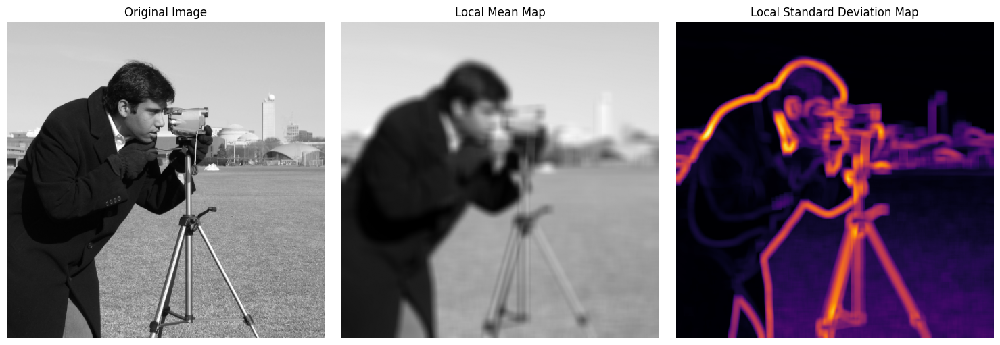

In [21]:
# Calculate Local Mean and Standard Deviation
gray_float = gray_img.astype(np.float32)
window_size = 15
local_mean = uniform_filter(gray_float, size=window_size, mode="reflect")
local_mean_square = uniform_filter(gray_float ** 2, size=window_size, mode="reflect")
local_variance = np.maximum(local_mean_square - local_mean ** 2, 0)
local_std = np.sqrt(local_variance)
global_mean = float(gray_float.mean())
global_std = float(gray_float.std())
print("Global mean:", global_mean)
print("Global standard deviation:", global_std)
print("Mean local standard deviation:", float(local_std.mean()))
 
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(gray_img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image")
axes[1].imshow(local_mean, cmap="gray"); axes[1].set_title("Local Mean Map")
axes[2].imshow(local_std, cmap="inferno"); axes[2].set_title("Local Standard Deviation Map")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()


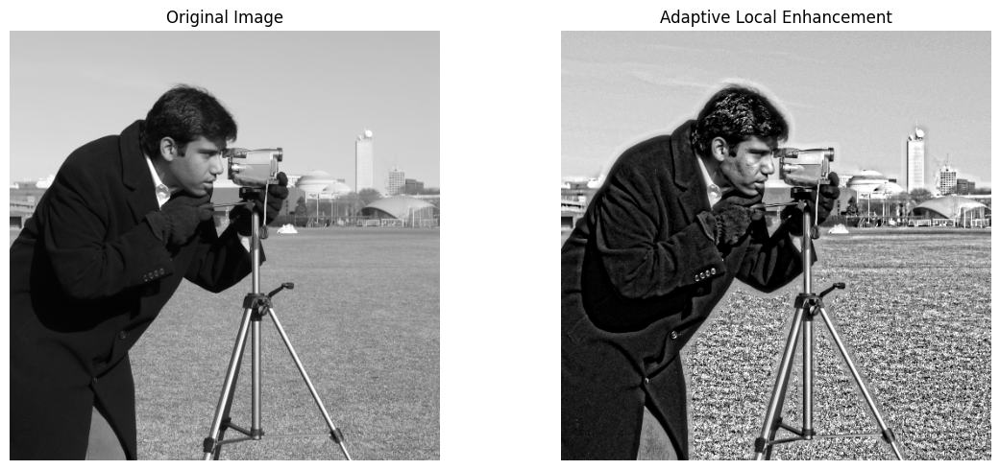

In [22]:
# Adaptive Local Enhancement
def adaptive_local_enhancement(gray, window_size=15, k=0.5):
    img = gray.astype(np.float32)
    local_mean = uniform_filter(img, size=window_size, mode="reflect")
    local_mean_square = uniform_filter(img ** 2, size=window_size, mode="reflect")
    local_variance = np.maximum(local_mean_square - local_mean ** 2, 0)
    local_std = np.sqrt(local_variance)
    global_mean = float(img.mean())
    gain = (k * global_mean) / np.maximum(local_std, 1.0)
    gain = np.clip(gain, 0.0, 5.0)
    enhanced = gain * (img - local_mean) + local_mean
    return np.clip(enhanced, 0, 255).astype(np.uint8)
 
adaptive_gray = adaptive_local_enhancement(gray_img, window_size=15, k=0.5)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(gray_img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image"); axes[0].axis("off")
axes[1].imshow(adaptive_gray, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Adaptive Local Enhancement"); axes[1].axis("off")
plt.tight_layout(); plt.show()


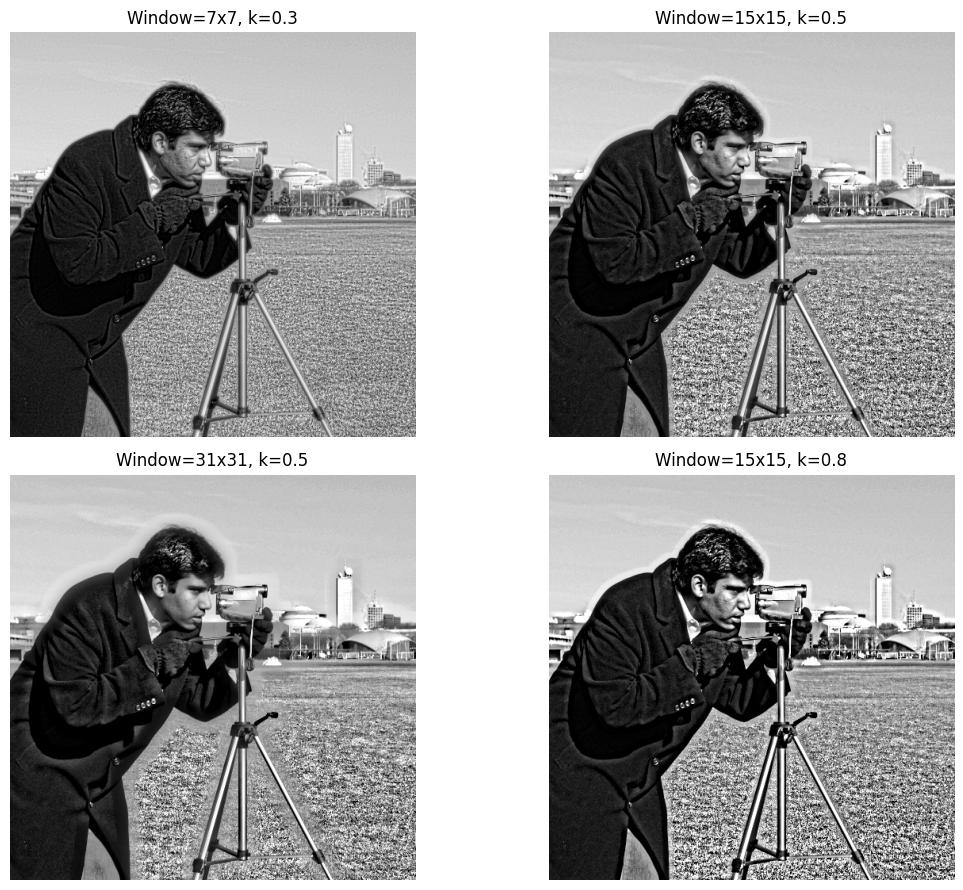

In [23]:
# Investigate Window Size and Gain
settings = [(7, 0.3), (15, 0.5), (31, 0.5), (15, 0.8)]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (window, k) in zip(axes.flat, settings):
    result = adaptive_local_enhancement(gray_img, window_size=window, k=k)
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Window={window}x{window}, k={k}")
    ax.axis("off")
plt.tight_layout(); plt.show()


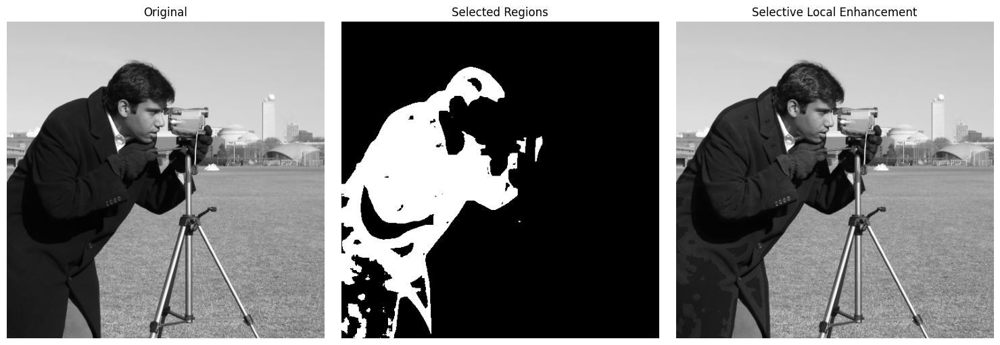

Percentage of pixels selected: 19.53 %


In [24]:
# Selective Local Enhancement Using Statistical Conditions
def selective_local_enhancement(
    gray, window_size=15, E=1.5, k0=0.4, k1=0.02, k2=0.4
):
    img = gray.astype(np.float32)
    local_mean = uniform_filter(img, size=window_size, mode="reflect")
    local_mean_square = uniform_filter(img ** 2, size=window_size, mode="reflect")
    local_variance = np.maximum(local_mean_square - local_mean ** 2, 0)
    local_std = np.sqrt(local_variance)
    global_mean, global_std = float(img.mean()), float(img.std())
 
    condition = (
        (local_mean <= k0 * global_mean) &
        (local_std >= k1 * global_std) &
        (local_std <= k2 * global_std)
    )
    result = img.copy()
    result[condition] = E * result[condition]
    return np.clip(result, 0, 255).astype(np.uint8), condition
 
selective_gray, selected_regions = selective_local_enhancement(
    gray_img, window_size=15, E=1.5, k0=0.4, k1=0.02, k2=0.4
)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(gray_img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(selected_regions, cmap="gray")
axes[1].set_title("Selected Regions"); axes[1].axis("off")
axes[2].imshow(selective_gray, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Selective Local Enhancement"); axes[2].axis("off")
plt.tight_layout(); plt.show()
print("Percentage of pixels selected:", round(100 * selected_regions.mean(), 2), "%")


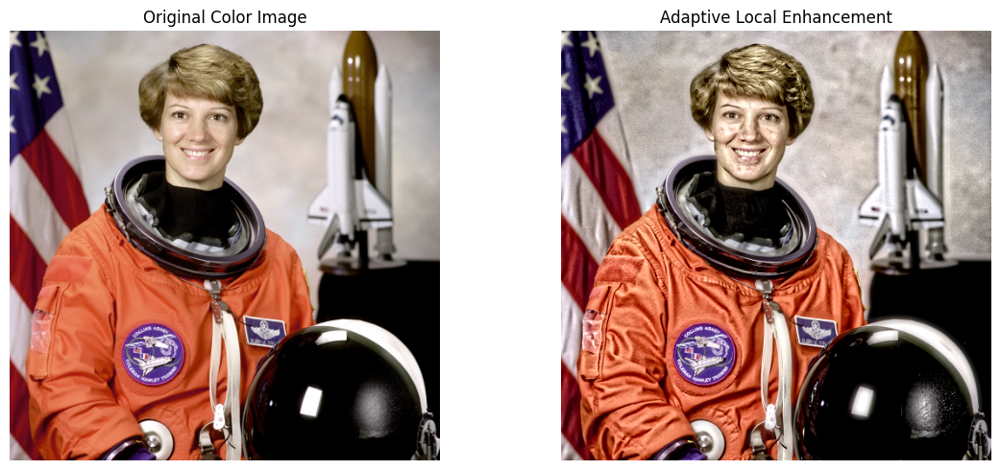

In [24]:
# Extend Local Statistical Enhancement to Color
ycrcb = cv2.cvtColor(color_img, cv2.COLOR_RGB2YCrCb)
y, cr, cb = cv2.split(ycrcb)
adaptive_y = adaptive_local_enhancement(y, window_size=15, k=0.5)
adaptive_color = cv2.cvtColor(
    cv2.merge([adaptive_y, cr, cb]), cv2.COLOR_YCrCb2RGB
)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(color_img); axes[0].set_title("Original Color Image"); axes[0].axis("off")
axes[1].imshow(adaptive_color); axes[1].set_title("Adaptive Local Enhancement"); axes[1].axis("off")
plt.tight_layout(); plt.show()


## Part F — Consolidated Comparison and Reporting

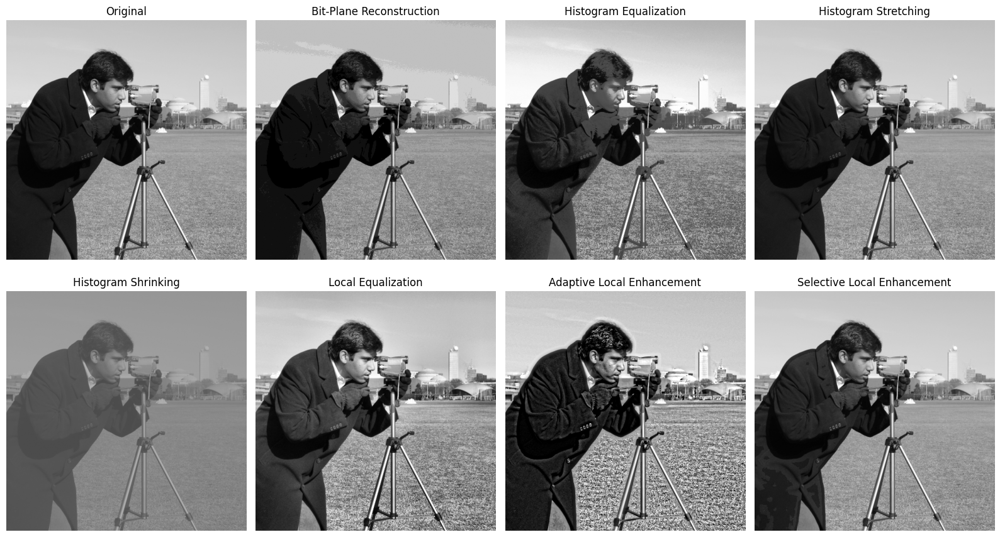

In [25]:
# Create a Final Comparison Panel
results = [
    ("Original", gray_img),
    ("Bit-Plane Reconstruction", reconstructed),
    ("Histogram Equalization", equalized_gray),
    ("Histogram Stretching", stretched_gray),
    ("Histogram Shrinking", shrunk_gray),
    ("Local Equalization", local_equalized),
    ("Adaptive Local Enhancement", adaptive_gray),
    ("Selective Local Enhancement", selective_gray)
]
fig, axes = plt.subplots(2, 4, figsize=(16, 9))
for ax, (title, img) in zip(axes.flat, results):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
